In [64]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from pymoo.indicators.hv import HV
from quantum_energy.problem.modeller import RedispatchModel
from quantum_energy.problem.qubo import RedispatchQUBO
from quantum_energy.problem.redispatch_stats import RedispatchStats
from quantum_energy.moo import filter_and_sort_pf
from quantum_energy.util import get_n_switches_mat

In [5]:
model_type = 'hours=2'

In [61]:
def get_sim_results(Rd):
    cost_mwh = Rd.prod_cost_multi
    return {
            "t": list(range(Rd.T)),
            "powers": Rd.prod_target,
            "costs": Rd.prod_resos.T @ cost_mwh,
            "overloads": np.sum(
                Rd.S_resos @ Rd.sim_res.reso_prods
                + Rd.S_sgens @ Rd.sim_res.sgen_prods
                + Rd.S_loads @ Rd.sim_res.load_prods
                > Rd.max_load,
                axis=0,
            ),
            "switches": get_n_switches_mat(Rd.prod_resos.T),
        }

In [97]:
np.full((8), np.nan)

array([nan, nan, nan, nan, nan, nan, nan, nan])

In [98]:
def get_row_per_stat(Rd, x):
    Rd_stats = RedispatchStats(Rd)
    row_per_stat = {k: np.full((8), np.nan) for k in ['powers', 'costs', 'overloads', 'switches', 't']}
    sim_res = get_sim_results(Rd)
    sol_res = Rd_stats.x_sol_to_stats_over_time(x)
    for t in range(len(sol_res['t'])):
        row_per_stat['t'][t] = sol_res['t'][t]
        row_per_stat['powers'][t] = sol_res['powers'][t] * 100
        row_per_stat['overloads'][t] = ((sol_res['overloads'][t]/sim_res['overloads'][t]) - 1)*100
        row_per_stat['costs'][t] = ((sol_res['costs'][t]/sim_res['costs'][t]) - 1)*100
        if t>0:
            row_per_stat['switches'][t] = ((sol_res['switches'][t]/sim_res['switches'][t]) - 1)*100
    return row_per_stat

In [100]:
sim_res = get_sim_results(Rd)

In [155]:
def load_res_df(res_name='tabu', n_run=3):
    xs = []
    for i in range(n_run):
        with open(f"../new_results/{model_type}/compare_{res_name}_xs_{i}.pkl", 'rb') as f:
            xs.append(pickle.load(f))
    stats = [get_row_per_stat(Rd, x) for x in xs]
    for i in range(len(stats)):
        stats[i]['solver'] = [res_name] * len(stats[i]['t'])
        stats[i]['run'] = [i] * len(stats[i]['t'])
    return pd.concat([pd.DataFrame(s) for s in stats]) 

In [185]:
res_tabu = load_res_df(n_run=3)

In [186]:
res_quant = load_res_df('quan', 3)

In [191]:
agg_res_tabu = res_tabu.groupby(["solver", "t"]).agg(['min', 'median', 'max'])
agg_res_tabu

powers                          costs                        \
                 min    median       max        min     median        max   
solver t                                                                    
tabu   0.0 -0.013783  0.004143  0.006684  13.089704  16.158118  19.494671   
       1.0 -0.014347  0.004009  0.015991  15.901643  16.873222  18.711849   
       2.0 -0.006493 -0.002919 -0.000281  13.116131  16.428739  19.586159   
       3.0 -0.006497 -0.005155 -0.004261   9.577178  11.759835  14.058110   
       4.0 -0.010210 -0.005314  0.020479   7.932596   8.000421  12.164130   
       5.0 -0.020183  0.002388  0.011251   7.594441   8.810904  13.233580   
       6.0 -0.025155 -0.015395 -0.012285   8.106022  11.432621  13.439477   
       7.0  0.002409  0.005500  0.062854   6.751327  11.247079  15.030971   

            overloads                           switches               \
                  min     median        max          min       median   
solver t                                                                
tabu   0.0  50.000000  75.000000  75.000000          NaN          NaN   
       1.0 -33.333333 -16.666667  16.666667  1963.636364  2027.272727   
       2.0 -33.333333 -16.666667   0.000000  3242.857143  3314.285714   
       3.0 -72.727273 -45.454545 -36.363636   464.444444   477.777778   
       4.0 -64.705882 -64.705882 -52.941176   651.724138   720.689655   
       5.0 -61.111111 -55.555556 -44.444444  7700.000000  7733.333333   
       6.0 -64.285714 -50.000000 -42.857143   812.000000   840.000000   
       7.0   0.000000   0.000000   0.000000   370.000000   380.000000   

                        run             
                    max min median max  
solver t                                
tabu   0.0          NaN   0    1.0   2  
       1.0  2081.818182   0    1.0   2  
       2.0  3342.857143   0    1.0   2  
       3.0   491.111111   0    1.0   2  
       4.0   751.724138   0    1.0   2  
       5.0  8000.000000   0    1.0   2  
       6.0   840.000000   0    1.0   2  
       7.0   388.333333   0    1.0   2

In [192]:
agg_res_quant = res_quant.groupby(["solver", "t"]).agg(['min', 'median', 'max'])
agg_res_quant

powers                          costs                        \
                 min    median       max        min     median        max   
solver t                                                                    
quan   0.0 -0.058157  0.037394  0.061530  17.318115  17.390146  20.610836   
       1.0 -0.127322 -0.053016  0.034233  20.976647  21.002636  21.153490   
       2.0 -0.035242  0.024013  0.298050  17.170464  17.179872  18.690163   
       3.0 -0.235862 -0.197878  0.029970   9.673365  11.891151  12.914845   
       4.0 -0.047952 -0.003427  0.079944   7.669706   9.516079   9.624909   
       5.0 -0.148827  0.082276  0.118245   8.835599   9.896467  10.039832   
       6.0 -0.222355 -0.047389  0.021765  10.507384  11.084445  14.397818   
       7.0  0.130945  0.272521  0.371407  14.762553  16.762875  19.573964   

            overloads                            switches               \
                  min     median         max          min       median   
solver t                                                                 
quan   0.0  50.000000  50.000000  100.000000          NaN          NaN   
       1.0  16.666667  16.666667   16.666667  2090.909091  2145.454545   
       2.0 -16.666667  16.666667   16.666667  3385.714286  3400.000000   
       3.0 -36.363636  -9.090909   -9.090909   473.333333   491.111111   
       4.0 -52.941176 -52.941176  -35.294118   762.068966   786.206897   
       5.0 -61.111111 -44.444444  -44.444444  8166.666667  8433.333333   
       6.0 -50.000000 -50.000000  -42.857143   904.000000   920.000000   
       7.0 -16.666667   0.000000   16.666667   355.000000   360.000000   

                        run             
                    max min median max  
solver t                                
quan   0.0          NaN   0    1.0   2  
       1.0  2190.909091   0    1.0   2  
       2.0  3471.428571   0    1.0   2  
       3.0   493.333333   0    1.0   2  
       4.0   806.896552   0    1.0   2  
       5.0  8866.666667   0    1.0   2  
       6.0   920.000000   0    1.0   2  
       7.0   366.666667   0    1.0   2

In [196]:
np.array([[1,2,3],[4,5,6]])

array([[1, 2, 3],
       [4, 5, 6]])

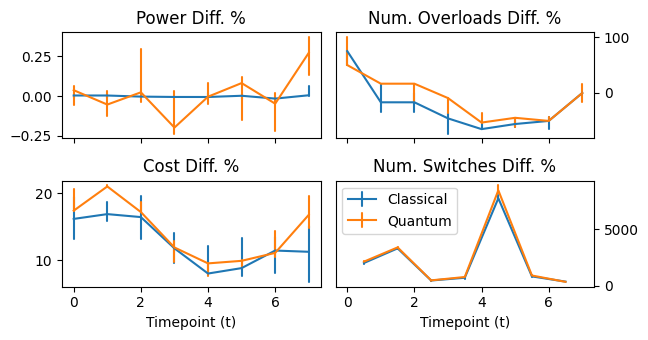

In [200]:
fig, ax = plt.subplots(2, 2, figsize=(6.5,3.5), sharex=True)
c = 0
for stat in ['powers', 'overloads', 'costs', 'switches']:
    i = c // 2
    j = c % 2
    ts = avg_res_tabu.index.get_level_values('t')
    if stat == "switches":
        ts = ts - 0.5
    for df, lab in [(agg_res_tabu, 'Classical'), (agg_res_quant, 'Quantum')]:
        medians = df[(stat, 'median')]
        ax[i][j].errorbar(ts, medians, yerr=[medians-df[(stat,'min')], df[(stat,'max')]-medians], label=lab)
    if stat == 'powers':
        ax[i][j].set_title("Power Diff. %")
    elif stat == 'overloads':
        ax[i][j].set_title("Num. Overloads Diff. %")
    elif stat == "costs":
        ax[i][j].set_title("Cost Diff. %")
    elif stat == "switches":
        ax[i][j].set_title("Num. Switches Diff. %")
    #ax[i][j].set_ylabel("% diff")
    if i == 1:
        ax[i][j].set_xlabel("Timepoint (t)")
    if j == 1:
        ax[i][j].yaxis.tick_right()
        ax[i][j].yaxis.set_label_position("right")
    if i == 1 and j == 1:
        ax[i][j].legend()
    c+=1
plt.tight_layout()
plt.savefig('./plots/compare-solvers.pdf', bbox_inches="tight")
plt.show()

In [14]:
tabu_xs = []
for i in range(3):
    with open(f"../new_results/hours=2/compare_tabu_xs_{i}.pkl", 'rb') as f:
        tabu_xs.append(pickle.load(f))

In [15]:
tabu_xs

[array([0., 1., 0., ..., 0., 0., 0.]),
 array([0., 0., 1., ..., 0., 1., 0.]),
 array([1., 0., 0., ..., 1., 0., 0.])]

In [16]:
tabu_stats = [Rd_stats.x_sol_to_stats_over_time(x) for x in tabu_xs]

In [19]:
for i in range(len(tabu_stats)):
    print(tabu_stats[i]['powers']*100)
    tabu_stats[i]['run'] = [i] * len(tabu_stats[i]['t'])

[ 0.00872192 -0.01285626 -0.0072488   0.00355442  0.02870547  0.00076978
  0.00804083  0.02656871]
[-0.02971605  0.0410877  -0.00372579  0.00480568  0.01135203 -0.00531414
 -0.02474191  0.03076791]
[-0.00516072  0.01379418  0.00728722  0.00121524  0.00352335 -0.0124895
  0.00950737  0.02381847]


In [21]:
tabu_df = pd.concat([pd.DataFrame(s) for s in tabu_stats])

In [22]:
tabu_df

,t,overloads,invalids,costs,powers,switches,run
0,0,6,0.0,1.441883e+06,0.000087,0,0
1,1,5,0.0,1.318404e+06,-0.000129,220,0
2,2,5,0.0,1.408195e+06,-0.000072,228,0
3,3,6,0.0,2.142378e+06,0.000036,241,0
4,4,7,0.0,2.451752e+06,0.000287,217,0
5,5,11,0.0,2.451210e+06,0.000008,231,0
6,6,8,0.0,2.204132e+06,0.000080,230,0
7,7,7,0.0,1.130574e+06,0.000266,268,0
0,0,9,0.0,1.443566e+06,-0.000297,0,1
1,1,7,0.0,1.316184e+06,0.000411,211,1
